In [ ]:
!pip install mujoco

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 232.8/232.8 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.2/30.2 MB 59.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.5/248.5 kB 17.7 MB/s eta 0:00:00


In [ ]:
# ============================================================
# CELL 1 — Configure MuJoCo for headless Colab rendering
# ============================================================

import os

# MUST be set before importing mujoco
os.environ["MUJOCO_GL"] = "egl"

# Colab has no X11 display
os.environ.pop("DISPLAY", None)

print("MUJOCO_GL =", os.environ["MUJOCO_GL"])
print("DISPLAY    =", os.environ.get("DISPLAY"))

MUJOCO_GL = egl
DISPLAY    = None


In [ ]:
# ============================================================
# CELL 2 — Imports
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import mujoco

print("MuJoCo version:", mujoco.__version__)
print("Rendering backend:", os.environ["MUJOCO_GL"])

MuJoCo version: 3.15.0
Rendering backend: egl


In [ ]:
# ============================================================
# CELL 3 — Test MuJoCo EGL rendering
# ============================================================

try:
    mujoco.GLContext(128, 128)
    print("✓ EGL/OpenGL context created successfully")
except Exception as e:
    print("✗ EGL initialization failed")
    print(type(e).__name__, ":", e)

✓ EGL/OpenGL context created successfully


In [ ]:
# Origami dimensions
L = 1.0          # sheet size
thickness = 0.015

# Two triangular panels
# Panel A: bottom-left -> bottom-right -> top-right
# Panel B: bottom-left -> top-right -> top-left

vertices = np.array([
    [0.0, 0.0, 0.0],   # 0
    [L,   0.0, 0.0],   # 1
    [L,   L,   0.0],   # 2
    [0.0, L,   0.0],   # 3
])

print(vertices)

[[0. 0. 0.]
 [1. 0. 0.]
 [1. 1. 0.]
 [0. 1. 0.]]


In [ ]:
xml = f"""
<mujoco model="origami">

    <compiler angle="radian" coordinate="local"/>

    <option timestep="0.002"
            gravity="0 0 -9.81"
            integrator="implicitfast"/>

    <visual>
        <global offwidth="1280"
                offheight="720"/>

        <quality shadowsize="2048"/>

        <headlight diffuse="0.8 0.8 0.8"
                    ambient="0.3 0.3 0.3"
                    specular="0.2 0.2 0.2"/>
    </visual>

    <asset>

        <material name="paper"
                  rgba="0.95 0.95 0.95 1"
                  specular="0.1"/>

        <material name="paper2"
                  rgba="0.75 0.85 1.0 1"
                  specular="0.1"/>

        <material name="ground"
                  rgba="0.15 0.15 0.15 1"/>

    </asset>

    <worldbody>

        <!-- Ground -->
        <geom name="ground"
              type="plane"
              size="5 5 0.1"
              pos="0 0 -0.02"
              material="ground"/>

        <!-- Fixed half of origami -->
        <body name="panel_A"
              pos="0 0 0">

            <geom name="triangle_A"
                  type="box"
                  size="{L/3} {L/3} {thickness/2}"
                  pos="{L/3} {L/3} 0"
                  material="paper"
                  contype="1"
                  conaffinity="1"/>

        </body>


        <!-- Folding half -->
        <body name="panel_B"
              pos="0 0 0">

            <!-- Hinge along diagonal -->
            <joint name="fold"
                   type="hinge"
                   axis="1 -1 0"
                   pos="0.5 0.5 0"
                   range="-2.8 2.8"
                   damping="0.2"
                   armature="0.001"/>

            <geom name="triangle_B"
                  type="box"
                  size="{L/3} {L/3} {thickness/2}"
                  pos="{L/3} {L/3} 0"
                  material="paper2"
                  contype="1"
                  conaffinity="1"/>

        </body>

    </worldbody>

    <actuator>

        <position name="fold_motor"
                  joint="fold"
                  kp="5"
                  kv="1"
                  ctrlrange="-2.5 2.5"
                  gear="1"/>

    </actuator>

</mujoco>
"""

print(xml[:1000])


<mujoco model="origami">

    <compiler angle="radian" coordinate="local"/>

    <option timestep="0.002"
            gravity="0 0 -9.81"
            integrator="implicitfast"/>

    <visual>
        <global offwidth="1280"
                offheight="720"/>

        <quality shadowsize="2048"/>

        <headlight diffuse="0.8 0.8 0.8"
                    ambient="0.3 0.3 0.3"
                    specular="0.2 0.2 0.2"/>
    </visual>

    <asset>

        <material name="paper"
                  rgba="0.95 0.95 0.95 1"
                  specular="0.1"/>

        <material name="paper2"
                  rgba="0.75 0.85 1.0 1"
                  specular="0.1"/>

        <material name="ground"
                  rgba="0.15 0.15 0.15 1"/>

    </asset>

    <worldbody>

        <!-- Ground -->
        <geom name="ground"
              type="plane"
              size="5 5 0.1"
              pos="0 0 -0.02"
              material="ground"/>

        <!-- Fixed half of origami -->
        

In [ ]:
# ============================================================
# CELL 4 — Load model
# ============================================================

model = mujoco.MjModel.from_xml_string(xml)
data = mujoco.MjData(model)

print("Bodies:", model.nbody)
print("Joints:", model.njnt)
print("Actuators:", model.nu)

Bodies: 3
Joints: 1
Actuators: 1


In [ ]:
# ============================================================
# CELL 5 — Create offscreen renderer
# ============================================================

renderer = mujoco.Renderer(
    model,
    height=720,
    width=1280
)

print("✓ Renderer initialized")

✓ Renderer initialized


Image shape: (720, 1280, 3)


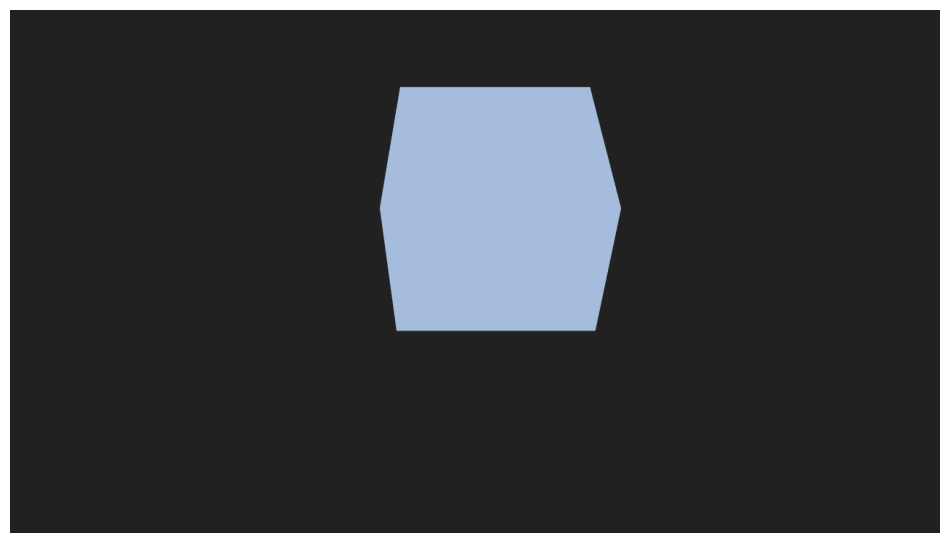

In [ ]:
# ============================================================
# CELL 6 — Render
# ============================================================

mujoco.mj_forward(model, data)

renderer.update_scene(data)

pixels = renderer.render()

print("Image shape:", pixels.shape)

plt.figure(figsize=(12, 7))
plt.imshow(pixels)
plt.axis("off")
plt.show()

In [ ]:
# ============================================================
# CELL 7 — Origami crease pattern
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Grid dimensions
rows = 4
cols = 4

# Origami dimensions
Lx = 2.0
Ly = 2.0

# Crease angle
theta = np.deg2rad(60)

vertices = []
faces = []
creases = []

# ------------------------------------------------------------
# Create vertices
# ------------------------------------------------------------

for r in range(rows + 1):
    for c in range(cols + 1):

        x = c * (Lx / cols)

        # Zig-zag / Miura displacement
        y = r * (Ly / rows)

        if r % 2:
            x += Lx / (2 * cols)

        vertices.append([x, y, 0.0])

vertices = np.array(vertices)

print("Vertices:", len(vertices))

Vertices: 25


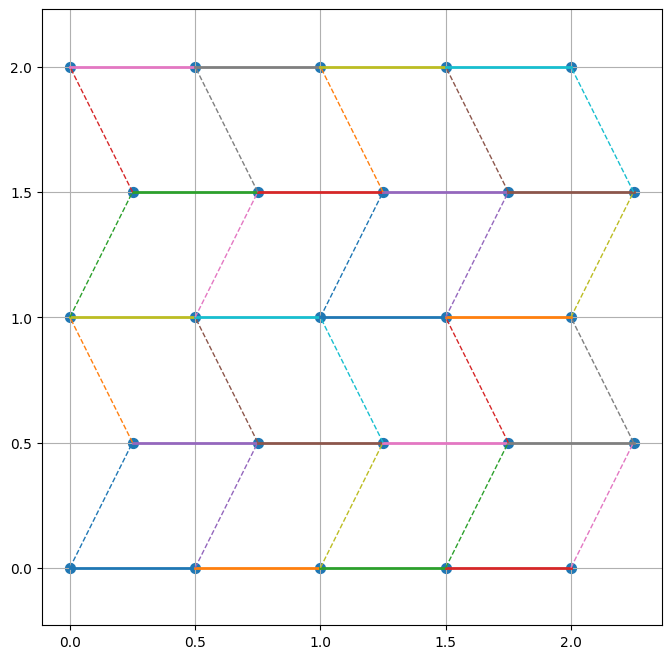

In [ ]:
# ============================================================
# CELL 8 — Visualize crease pattern
# ============================================================

fig = plt.figure(figsize=(8, 8))

plt.scatter(
    vertices[:, 0],
    vertices[:, 1],
    s=50
)

for r in range(rows + 1):
    for c in range(cols):

        i = r * (cols + 1) + c
        j = i + 1

        plt.plot(
            [vertices[i, 0], vertices[j, 0]],
            [vertices[i, 1], vertices[j, 1]],
            linewidth=2
        )

for c in range(cols + 1):
    for r in range(rows):

        i = r * (cols + 1) + c
        j = i + cols + 1

        if i < len(vertices) and j < len(vertices):

            plt.plot(
                [vertices[i, 0], vertices[j, 0]],
                [vertices[i, 1], vertices[j, 1]],
                linestyle="--",
                linewidth=1
            )

plt.axis("equal")
plt.grid()
plt.show()

In [ ]:
xml_fold = """
<mujoco model="origami_fold">

    <option
        timestep="0.002"
        gravity="0 0 -9.81"
        integrator="implicitfast"/>

    <visual>
        <global
            offwidth="1280"
            offheight="720"/>
    </visual>

    <asset>

        <!-- Paper -->
        <material
            name="paper_A"
            rgba="0.85 0.90 1.0 1"
            specular="0.1"/>

        <material
            name="paper_B"
            rgba="1.0 0.85 0.85 1"
            specular="0.1"/>


        <!-- MuJoCo-style checkerboard -->
        <texture
            name="checker"
            type="2d"
            builtin="checker"
            width="512"
            height="512"
            rgb1="0.1 0.1 0.1"
            rgb2="0.8 0.8 0.8"/>

        <material
            name="floor"
            texture="checker"
            texrepeat="8 8"
            reflectance="0.1"
            specular="0.2"/>

    </asset>


    <worldbody>

        <!-- ==========================================
             CHECKERBOARD FLOOR
             ========================================== -->

        <geom
            name="ground"
            type="plane"
            size="5 5 0.05"
            pos="0 0 -0.03"
            material="floor"
            contype="1"
            conaffinity="1"/>


        <!-- ==========================================
             FIXED PANEL
             ========================================== -->

<body name="panel_A" pos="0 0 0">

    <geom
        name="panel_A_geom"
        type="box"
        size="0.5 0.5 0.01"
        pos="0.5 0 1"
        material="paper_A"
        contype="0"
        conaffinity="0"/>

</body>


        <!-- ==========================================
             FOLDING PANEL
             ========================================== -->

<body name="panel_B" pos="0 0 0">

    <joint
        name="crease_0"
        type="hinge"
        pos="0 0 0"
        axis="0 1 0"
        range="-1.57 1.57"
        damping="0.1"/>

    <geom
        name="panel_B_geom"
        type="box"
        size="0.5 0.5 0.01"
        pos="-0.5 0 1"
        material="paper_B"
        contype="0"
        conaffinity="0"/>

</body>

    </worldbody>


<actuator>

    <position
        name="fold_actuator"
        joint="crease_0"
        kp="200"
        kv="10"
        ctrlrange="-1.57 1.57"
        forcerange="-100 100"/>

</actuator>

</mujoco>
"""

crease pattern generator


In [ ]:
from dataclasses import dataclass
import numpy as np

@dataclass
class Crease:
    x: float            # position along the sheet (0 .. width)
    kind: str           # "M" = mountain, "V" = valley
    angle: float = 180  # target fold angle in degrees

# ---- Sheet ----
SHEET_W = 1.0           # along x (folding direction)
SHEET_H = 1.0           # along y
Z0      = 0.03           # height of the sheet above the floor

# ---- Table vibration ----
VIB_FREQ    = 30.0     # Hz
VIB_AMP_X   = 0.0   # m, horizontal (this is what drags the paper by friction)
VIB_AMP_Z   = 0.05     # m, vertical (set > 0 for bouncing)

# ---- Friction (paper on table is roughly 0.3 - 0.5) ----
MU_PAPER = 0.4
MU_TABLE = 0.4


# ---- Crease pattern (edit freely) ----
# Single fold, like your original XML:
# creases = [Crease(0.5, "V", 90)]

# Accordion / zig-zag fold:
creases = [
    Crease(0.20, "V", 150),
    Crease(0.40, "M", 150),
    Crease(0.60, "V", 150),
    Crease(0.80, "M", 150),
]

creases = sorted(creases, key=lambda c: c.x)
edges   = [0.0] + [c.x for c in creases] + [SHEET_W]
widths  = np.diff(edges)
print("Panel widths:", np.round(widths, 3))

Panel widths: [0.2 0.2 0.2 0.2 0.2]


In [ ]:


def generate_xml(creases, widths, sheet_h=1.0, z0=1.0, thickness=0.0001,
                 kp=200, kv=10, damping=0.1, name="origami_fold",
                 mu_paper=0.4, mu_table=0.4):
    n = len(widths)
    total_w = float(np.sum(widths))
    mats = ["paper_A", "paper_B"]

    # Sign convention: positive hinge angle about +y rotates the next panel
    # downward -> mountain fold (seen from above). Valley = negative.
    def signed(c):
        a = np.radians(c.angle)
        return a if c.kind.upper() == "M" else -a

    lines = []
    ind = lambda k: "    " * k

    # ---- header + assets ----
    lines.append(f'''<mujoco model="{name}">

    <option timestep="0.002" gravity="0 0 -9.81" integrator="implicitfast"/>

    <visual>
        <global offwidth="1280" offheight="720"/>
    </visual>

    <asset>
        <material name="paper_A" rgba="0.85 0.90 1.0 1" specular="0.1"/>
        <material name="paper_B" rgba="1.0 0.85 0.85 1" specular="0.1"/>

        <texture name="checker" type="2d" builtin="checker" width="512" height="512"
                 rgb1="0.1 0.1 0.1" rgb2="0.8 0.8 0.8"/>
        <material name="floor" texture="checker" texrepeat="8 8" reflectance="0.1" specular="0.2"/>
    </asset>

    <worldbody>
        <body name="table" pos="0 0 -0.05">
            <joint name="table_x" type="slide" axis="1 0 0" damping="0"/>
            <joint name="table_z" type="slide" axis="0 0 1" damping="0"/>
            <geom name="ground" type="box" size="5 5 0.05" material="floor"
                  contype="1" conaffinity="1" condim="3"
                  friction="{mu_table} 0.005 0.0001" mass="1000"/>
        </body>
''')

    # ---- nested panels: body origin sits on the panel's left edge (the hinge) ----
    depth = 2
    for i, w in enumerate(widths):
        pos = f"{-total_w/2} 0 {z0}" if i == 0 else f"{widths[i-1]} 0 0"
        lines.append(f'{ind(depth)}<body name="panel_{i}" pos="{pos}">')
        depth += 1

        if i == 0:
            # No fixed panel: the whole sheet is free to move
            lines.append(f'{ind(depth)}<freejoint name="root"/>')
        else:
            lines.append(
                f'{ind(depth)}<joint name="crease_{i-1}" type="hinge" pos="0 0 0" '
                f'axis="0 1 0" range="{-np.pi:.4f} {np.pi:.4f}" damping="{damping}"/>')
        lines.append(
            f'{ind(depth)}<geom name="panel_{i}_geom" type="box" '
            f'size="{w/2:.5f} {sheet_h/2:.5f} {thickness}" pos="{w/2:.5f} 0 0" '
            f'material="{mats[i % 2]}" contype="1" conaffinity="0" condim="3" '
            f'friction="{mu_paper} 0.005 0.0001" mass="0.05"/>')

    for _ in range(n):
        depth -= 1
        lines.append(f'{ind(depth)}</body>')

    lines.append('    </worldbody>\n')

    # ---- actuators ----
    lines.append('    <actuator>')
    for i in range(len(creases)):
        lines.append(
            f'        <position name="fold_{i}" joint="crease_{i}" kp="{kp}" kv="{kv}" '
            f'ctrlrange="{-np.pi:.4f} {np.pi:.4f}" forcerange="-100 100"/>')
    lines.append('    </actuator>\n</mujoco>')

    return "\n".join(lines)

xml_fold = generate_xml(creases, widths, SHEET_H, Z0,
                        mu_paper=MU_PAPER, mu_table=MU_TABLE)
target_angles = np.array([np.radians(c.angle) * (1 if c.kind.upper() == "M" else -1)
                          for c in creases])
print(xml_fold)

<mujoco model="origami_fold">

    <option timestep="0.002" gravity="0 0 -9.81" integrator="implicitfast"/>

    <visual>
        <global offwidth="1280" offheight="720"/>
    </visual>

    <asset>
        <material name="paper_A" rgba="0.85 0.90 1.0 1" specular="0.1"/>
        <material name="paper_B" rgba="1.0 0.85 0.85 1" specular="0.1"/>

        <texture name="checker" type="2d" builtin="checker" width="512" height="512"
                 rgb1="0.1 0.1 0.1" rgb2="0.8 0.8 0.8"/>
        <material name="floor" texture="checker" texrepeat="8 8" reflectance="0.1" specular="0.2"/>
    </asset>

    <worldbody>
        <body name="table" pos="0 0 -0.05">
            <joint name="table_x" type="slide" axis="1 0 0" damping="0"/>
            <joint name="table_z" type="slide" axis="0 0 1" damping="0"/>
            <geom name="ground" type="box" size="5 5 0.05" material="floor"
                  contype="1" conaffinity="1" condim="3"
                  friction="0.4 0.005 0.0001" mass="1000"

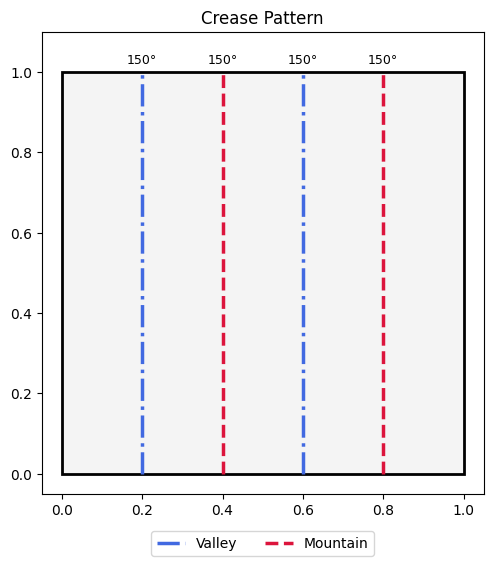

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

def plot_crease_pattern(creases, sheet_w, sheet_h):
    fig, ax = plt.subplots(figsize=(6, 6 * sheet_h / sheet_w))
    ax.add_patch(Rectangle((0, 0), sheet_w, sheet_h, fc="#f4f4f4", ec="k", lw=2))

    style = {"M": dict(color="crimson",   ls="--", label="Mountain"),
             "V": dict(color="royalblue", ls="-.", label="Valley")}
    used = set()
    for c in creases:
        k = c.kind.upper()
        ax.plot([c.x, c.x], [0, sheet_h], lw=2.5,
                label=style[k]["label"] if k not in used else None,
                color=style[k]["color"], ls=style[k]["ls"])
        ax.text(c.x, sheet_h + 0.02 * sheet_h, f"{c.angle:.0f}°",
                ha="center", fontsize=9)
        used.add(k)

    ax.set_xlim(-0.05, sheet_w + 0.05)
    ax.set_ylim(-0.05, sheet_h * 1.1)
    ax.set_aspect("equal")
    ax.set_title("Crease Pattern")
    ax.legend(loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.15))
    plt.show()

plot_crease_pattern(creases, SHEET_W, SHEET_H)

In [ ]:
!pip install mediapy

In [ ]:
# ============================================================
# CELL 4 — Build MuJoCo model from generated XML
# ============================================================

import mujoco
import mediapy as media

model_fold = mujoco.MjModel.from_xml_string(xml_fold)
data_fold  = mujoco.MjData(model_fold)

hinge_adr = np.array([
    model_fold.joint(f"crease_{i}").qposadr[0]
    for i in range(len(creases))
])

tx_qpos = model_fold.joint("table_x").qposadr[0]
tz_qpos = model_fold.joint("table_z").qposadr[0]
tx_dof  = model_fold.joint("table_x").dofadr[0]
tz_dof  = model_fold.joint("table_z").dofadr[0]

print("Hinge qpos index:", hinge_adr)
print("Table qpos (x, z):", tx_qpos, tz_qpos)
print("Target angles (deg):", np.round(np.rad2deg(target_angles), 1))

Hinge qpos index: [ 9 10 11 12]
Table qpos (x, z): 0 1
Target angles (deg): [-150.  150. -150.  150.]


In [ ]:
# ============================================================
# CELL 5 — Fold to full crease pattern
# ============================================================

mujoco.mj_resetData(model_fold, data_fold)

data_fold.ctrl[:] = target_angles

for _ in range(2000):
    mujoco.mj_step(
        model_fold,
        data_fold
    )

print(
    "Actual angles:",
    np.round(np.rad2deg(data_fold.qpos[hinge_adr]), 2),
    "degrees"
)

Actual angles: [0. 0. 0. 0.] degrees


""

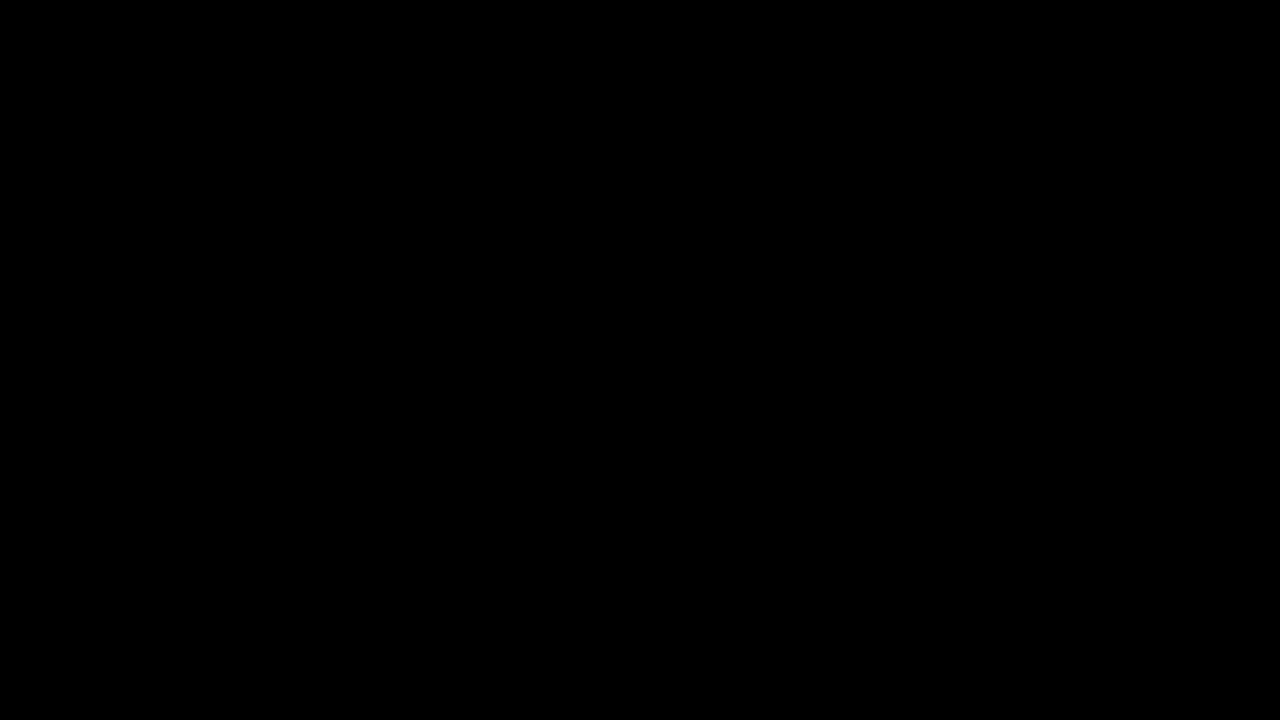

In [ ]:
# ============================================================
# CELL 6 — Render folded state
# ============================================================

renderer = mujoco.Renderer(model_fold, 720, 1280)

cam = mujoco.MjvCamera()
cam.lookat[:] = [0, 0, 0.3]
cam.distance  = 3.0
cam.azimuth   = 90
cam.elevation = -25

mujoco.mj_forward(model_fold, data_fold)
renderer.update_scene(data_fold, camera=cam)

media.show_image(renderer.render())


In [ ]:
# ============================================================
# CELL 7 — Fold all creases to 90 degrees
# ============================================================

mujoco.mj_resetData(model_fold, data_fold)

target = np.deg2rad(90)

# keep mountain (+) / valley (-) sign from the crease pattern
data_fold.ctrl[:] = np.sign(target_angles) * target

for _ in range(1000):
    mujoco.mj_step(
        model_fold,
        data_fold
    )

print(
    "Actual angles:",
    np.round(np.rad2deg(data_fold.qpos[hinge_adr]), 2),
    "degrees"
)

Actual angles: [0. 0. 0. 0.] degrees


In [ ]:
# ============================================================
# CELL 8 — Unfold to flat (0 degrees)
# ============================================================

target = np.deg2rad(0)

data_fold.ctrl[:] = target

for _ in range(1000):
    mujoco.mj_step(
        model_fold,
        data_fold
    )

print(
    "Actual angles:",
    np.round(np.rad2deg(data_fold.qpos[hinge_adr]), 2),
    "degrees"
)

Actual angles: [0. 0. 0. 0.] degrees


In [ ]:
# ============================================================
# CELL 9 — Animate the fold (flat -> folded)
# ============================================================

mujoco.mj_resetData(model_fold, data_fold)

FPS     = 30
T_FOLD  = 4.0
T_TOTAL = 6.0

frames = []

while data_fold.time < T_TOTAL:

    t = min(data_fold.time / T_FOLD, 1.0)
    s = t * t * (3 - 2 * t)          # smoothstep 0 -> 1

    data_fold.ctrl[:] = s * target_angles

    mujoco.mj_step(
        model_fold,
        data_fold
    )

    if len(frames) < data_fold.time * FPS:
        renderer.update_scene(data_fold, camera=cam)
        frames.append(renderer.render())

media.show_video(frames, fps=FPS)

print(
    "Final angles:",
    np.round(np.rad2deg(data_fold.qpos[hinge_adr]), 2),
    "degrees"
)


This browser does not support the video tag.


Final angles: [-146.2   145.17 -145.17  146.2 ] degrees


In [ ]:
# ============================================================
# CELL 10 — Save XML and video
# ============================================================

with open("origami_fold.xml", "w") as f:
    f.write(xml_fold)

media.write_video("origami_fold.mp4", frames, fps=FPS)

print("Saved: origami_fold.xml, origami_fold.mp4")

Saved: origami_fold.xml, origami_fold.mp4


In [ ]:
# ============================================================
# CELL 11 — Vibrating table + folding paper
# ============================================================

def drive_table(data, t):
    """Kinematically drive the table: position and velocity must match."""
    w = 2 * np.pi * VIB_FREQ

    data.qpos[tx_qpos] = VIB_AMP_X * np.sin(w * t)
    data.qvel[tx_dof]  = VIB_AMP_X * w * np.cos(w * t)

    data.qpos[tz_qpos] = VIB_AMP_Z * np.sin(w * t)
    data.qvel[tz_dof]  = VIB_AMP_Z * w * np.cos(w * t)


mujoco.mj_resetData(model_fold, data_fold)

renderer = mujoco.Renderer(model_fold, 720, 1280)
cam = mujoco.MjvCamera()
cam.lookat[:] = [0, 0, 0.1]
cam.distance, cam.azimuth, cam.elevation = 2.5, 90, -30

FPS, T_FOLD, T_TOTAL = 30, 3.0, 8.0
frames = []

root_adr = model_fold.joint("root").qposadr[0]

while data_fold.time < T_TOTAL:

    # fold ramp (smoothstep)
    t = min(data_fold.time / T_FOLD, 1.0)
    s = t * t * (3 - 2 * t)
    data_fold.ctrl[:] = s * target_angles

    # shake the table
    drive_table(data_fold, data_fold.time)

    mujoco.mj_step(model_fold, data_fold)

    if len(frames) < data_fold.time * FPS:
        renderer.update_scene(data_fold, camera=cam)
        frames.append(renderer.render())

media.show_video(frames, fps=FPS)

print("Paper position (x, y, z):", np.round(data_fold.qpos[root_adr:root_adr+3], 4))
print("Table x offset          :", round(data_fold.qpos[tx_qpos], 4))
print("Hinge angles (deg)      :", np.round(np.rad2deg(data_fold.qpos[hinge_adr]), 2))

This browser does not support the video tag.


Paper position (x, y, z): [2.512  0.     0.2535]
Table x offset          : 0.0
Hinge angles (deg)      : [-146.24  145.19 -145.35  146.2 ]


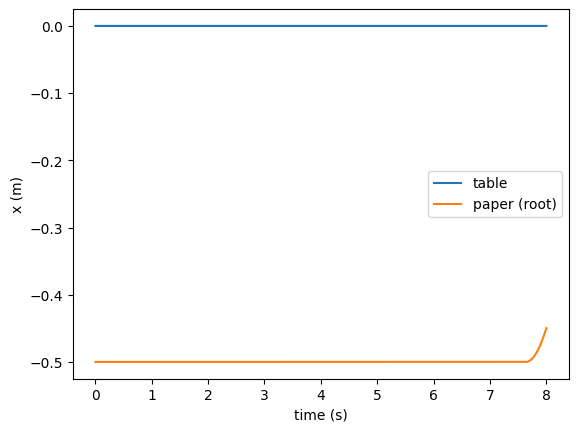

In [ ]:
# ============================================================
# CELL 12 — Paper vs table motion
# ============================================================

import matplotlib.pyplot as plt

mujoco.mj_resetData(model_fold, data_fold)
ts, paper_x, table_x = [], [], []

while data_fold.time < T_TOTAL:
    data_fold.ctrl[:] = 0
    drive_table(data_fold, data_fold.time)
    mujoco.mj_step(model_fold, data_fold)
    ts.append(data_fold.time)
    paper_x.append(data_fold.qpos[root_adr])
    table_x.append(data_fold.qpos[tx_qpos])

plt.plot(ts, table_x, label="table")
plt.plot(ts, paper_x, label="paper (root)")
plt.xlabel("time (s)"); plt.ylabel("x (m)"); plt.legend(); plt.show()

ini yang dari chgatgot

In [ ]:
# ============================================================
# CELL 10 — Load folding model
# ============================================================

model_fold = mujoco.MjModel.from_xml_string(xml_fold)
data_fold = mujoco.MjData(model_fold)

print("Joints:", model_fold.njnt)
print("Actuators:", model_fold.nu)

Joints: 4
Actuators: 4


In [ ]:
# ============================================================
# CELL 11 — Renderer
# ============================================================

renderer_fold = mujoco.Renderer(
    model_fold,
    height=720,
    width=1280
)

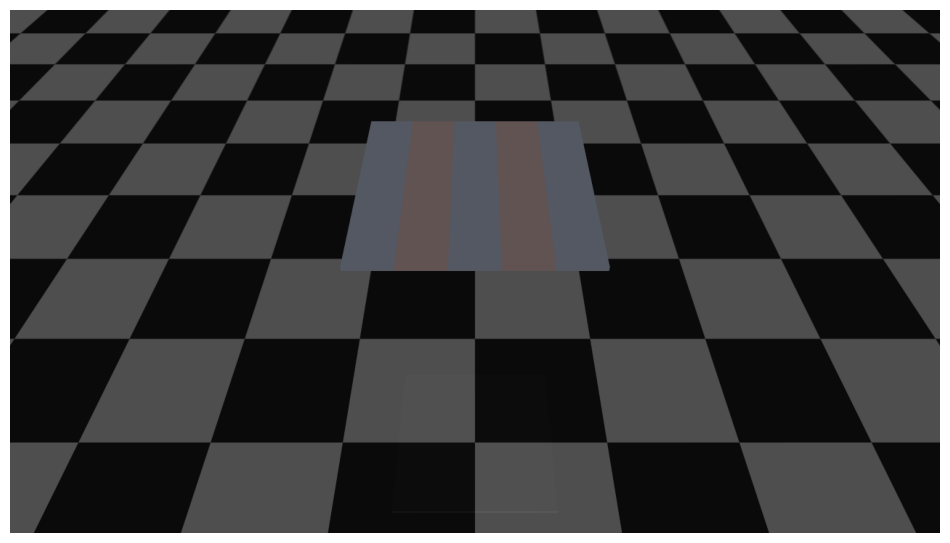

In [ ]:
# ============================================================
# CELL 12 — Flat state
# ============================================================

data_fold.qpos[0] = 0

mujoco.mj_forward(
    model_fold,
    data_fold
)

renderer_fold.update_scene(data_fold)

frame = renderer_fold.render()

plt.figure(figsize=(12, 7))
plt.imshow(frame)
plt.axis("off")
plt.show()

In [ ]:
# ============================================================
# CELL 13 — Fold to 90 degrees
# ============================================================

target = np.deg2rad(0)

data_fold.ctrl[0] = target

for _ in range(1000):
    mujoco.mj_step(
        model_fold,
        data_fold
    )

print(
    "Actual angle:",
    np.rad2deg(data_fold.qpos[0]),
    "degrees"
)

Actual angle: 3.70676309852336 degrees


In [ ]:
mujoco.mj_resetData(model_fold, data_fold)

data_fold.ctrl[0] = np.deg2rad(90)

for i in range(1000):
    mujoco.mj_step(model_fold, data_fold)

print("Target:",
      np.rad2deg(data_fold.ctrl[0]))

print("Actual:",
      np.rad2deg(data_fold.qpos[0]))

Target: 90.0
Actual: 1.5707003058646092


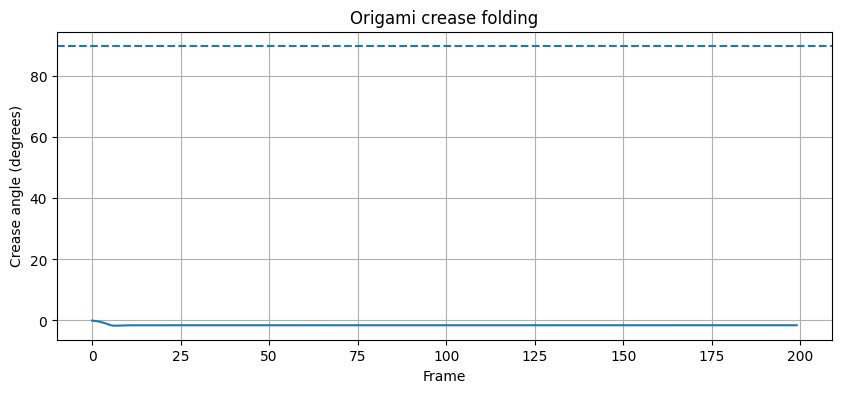

In [ ]:
angles = []

mujoco.mj_resetData(model_fold, data_fold)

for i in range(200):

    target = np.deg2rad(90) * i / 199

    data_fold.ctrl[0] = target

    for _ in range(10):
        mujoco.mj_step(model_fold, data_fold)

    angles.append(
        np.rad2deg(data_fold.qpos[0])
    )

plt.figure(figsize=(10, 4))

plt.plot(angles)

plt.axhline(
    90,
    linestyle="--"
)

plt.xlabel("Frame")
plt.ylabel("Crease angle (degrees)")
plt.title("Origami crease folding")

plt.grid()
plt.show()

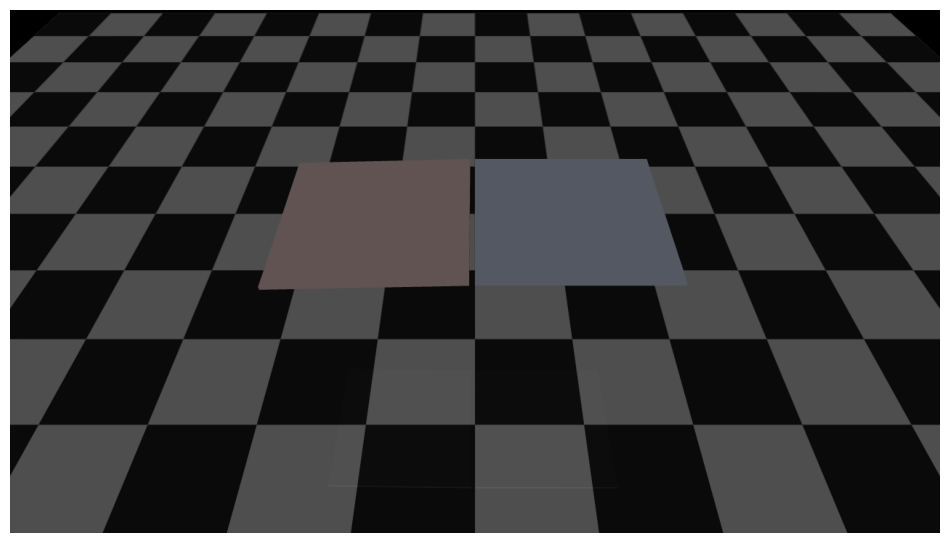

In [ ]:
# ============================================================
# CELL 14 — Render folded state
# ============================================================

renderer_fold.update_scene(data_fold)

frame = renderer_fold.render()

plt.figure(figsize=(12, 7))
plt.imshow(frame)
plt.axis("off")
plt.show()

In [ ]:
# ============================================================
# CELL 15 — Reset simulation
# ============================================================

mujoco.mj_resetData(model_fold, data_fold)

# Start completely flat
data_fold.qpos[0] = 0.0

mujoco.mj_forward(model_fold, data_fold)

print("Starting angle:",
      np.rad2deg(data_fold.qpos[0]))

Starting angle: 0.0


In [ ]:
# ============================================================
# CELL 16 — Generate folding video frames
# ============================================================

import imageio.v2 as imageio

frames = []

# Simulation settings
n_frames = 150
steps_per_frame = 10

start_angle = 0.0
end_angle = np.deg2rad(120)

for i in range(n_frames):

    # Smooth interpolation
    t = i / (n_frames - 1)

    # Smoothstep
    t_smooth = t * t * (3 - 2 * t)

    target_angle = (
        start_angle
        + (end_angle - start_angle) * t_smooth
    )

    # Command the crease
    data_fold.ctrl[0] = target_angle

    # Physics
    for _ in range(steps_per_frame):
        mujoco.mj_step(
            model_fold,
            data_fold
        )

    # Render
    renderer_fold.update_scene(
        data_fold
    )

    frame = renderer_fold.render().copy()

    frames.append(frame)

print("Generated frames:", len(frames))

Generated frames: 150


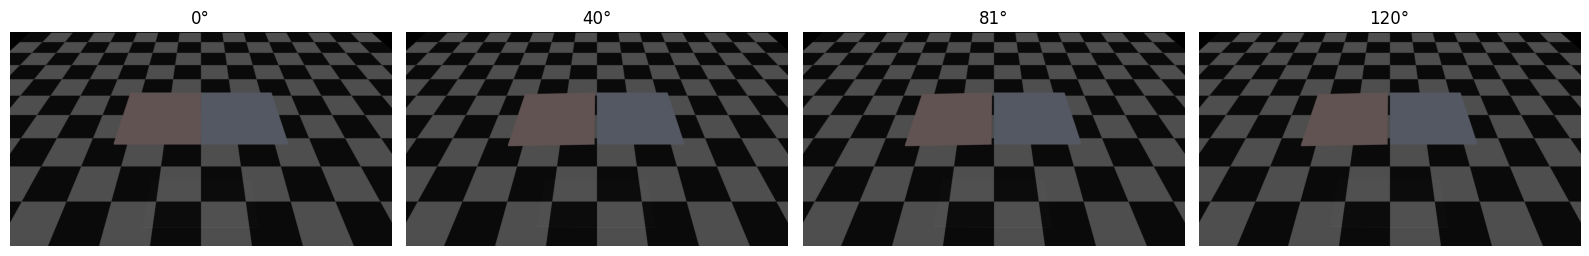

In [ ]:
# ============================================================
# CELL 17 — Preview
# ============================================================

fig, axes = plt.subplots(
    1, 4,
    figsize=(16, 4)
)

indices = [
    0,
    n_frames // 3,
    2 * n_frames // 3,
    n_frames - 1
]

for ax, idx in zip(axes, indices):

    ax.imshow(frames[idx])

    ax.set_title(
        f"{np.rad2deg(end_angle) * idx/(n_frames-1):.0f}°"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 18 — Save MP4
# ============================================================

video_path = "/content/origami_folding.mp4"

imageio.mimsave(
    video_path,
    frames,
    fps=30,
    codec="libx264"
)

print("Saved:", video_path)

Saved: /content/origami_folding.mp4


In [ ]:
# ============================================================
# CELL 19 — Display video
# ============================================================

from IPython.display import Video

Video(
    video_path,
    embed=True,
    width=960
)